In [1]:

# =============================================================================
# NOTEBOOK 4: MASTER CLINICAL DASHBOARD
# ISIC 2019 — Unified XAI Inference & Triage Pipeline
# =============================================================================
# PURPOSE : Combine all prior notebooks into one end-to-end clinical tool.
#           Given a raw skin lesion image (or a batch), the pipeline:
#             1. Runs calibrated ensemble inference
#             2. Computes MC-Dropout uncertainty
#             3. Generates the fused XAI heatmap
#             4. Applies clinical triage logic
#             5. Prints / saves a structured diagnostic report
#
# INPUTS  : A raw image path (or test CSV)
#           temperature_params.json   (from Notebook 3)
#           All 3 trained model .pth  (from Binary Classification)
#
# OUTPUTS : /kaggle/working/clinical_reports/
#               report_<image_id>.png   ← per-image visual report
#               final_clinical_report.csv ← triage decisions for all images
# =============================================================================



In [2]:
# ── CELL 1 : Imports ──────────────────────────────────────────────────────────
import os, gc, json, warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.cm as cm
from pathlib import Path
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm

warnings.filterwarnings('ignore')
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")

STAGE_NAMES = {'AK': 0, 'BCC': 1, 'SCC': 2, 'MEL': 3}




Device: cuda


In [3]:
# ── CELL 2 : Configuration ─────────────────────────────────────────────────────
INPUT_CSV_DIR   = '/kaggle/input/notebooks/nandini143/data-preparation'
MODEL_DIR       = '/kaggle/input/notebooks/bhavikadlecha'
UQ_PARAMS_PATH  = '/kaggle/input/notebooks/bhavikakadlecha/notebook3-uncertainty-calibration/xai_outputs/temperature_params.json'
OUTPUT_DIR      = '/kaggle/working/clinical_reports'
XAI_DIR         = os.path.join(MODEL_DIR, 'heatmap-output-binary/xai_outputs')
BINARY_HEATMAP_DIR = '/kaggle/input/datasets/bhavikakadlecha/heatmap-binary/xai_outputs/binary'
MULTI_HEATMAP_DIR  = '/kaggle/input/datasets/bhavikakadlecha/severity-heatmap-output/xai_outputs/multiclass'
MULTI_HEATMAP_DIR_2 = '/kaggle/input/notebooks/bhavikakadlecha/swin-only/xai_outputs/multiclass'
DENSENET_CKPT   = '/kaggle/input/notebooks/nandini143/binary-densenet-121/densenet121_best.pth'
EFFNET_CKPT     = '/kaggle/input/notebooks/nandini143/binary-efficientnetv2s/efficientnetv2s_best.pth'
SWIN_CKPT       = '/kaggle/input/notebooks/nandini143/binary-swin-tiny-transformer/swin_tiny_best.pth'
CONVNEXT_CKPT   = '/kaggle/input/notebooks/nandini143/binary-convnext/convnext_tiny_best.pth'
RESNET_CKPT     = '/kaggle/input/notebooks/nandini143/binary-resnet-200d/resnet200d_best.pth'

IMG_SIZE_CNN    = 384
IMG_SIZE_SWIN   = 224
MC_RUNS         = 30
IMAGENET_MEAN   = [0.485, 0.456, 0.406]
IMAGENET_STD    = [0.229, 0.224, 0.225]
OLD_PATH        = '/kaggle/working/preprocessed/'
NEW_PATH        = f'{INPUT_CSV_DIR}/preprocessed/'

# Clinical triage thresholds
UNCERTAINTY_THRESHOLD = 0.005    # variance above this → Manual Review

# Try loading dynamic threshold from Notebook 3
dynamic_thresh_path = os.path.join(os.path.dirname(UQ_PARAMS_PATH), 'dynamic_threshold.json')
if os.path.exists(dynamic_thresh_path):
    with open(dynamic_thresh_path, 'r') as f:
        dt = json.load(f)
        UNCERTAINTY_THRESHOLD = dt.get('UNCERTAINTY_THRESHOLD', 0.005)
        print(f"Loaded dynamic UNCERTAINTY_THRESHOLD: {UNCERTAINTY_THRESHOLD:.5f}")
CONFIDENCE_THRESHOLD  = 0.35    # prob above this → Malignant prediction
AUTO_DIAG_MIN_CONF    = 0.80    # confidence must be this high for Auto-Diagnosis

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Load temperature params from Notebook 3
with open(UQ_PARAMS_PATH) as f:
    TEMP_PARAMS = json.load(f)
print("Temperature params loaded:", {k: round(v['temperature'],4)
                                      for k, v in TEMP_PARAMS.items()})



# Define metadata columns for dummy_meta creation
val_df = pd.read_csv(os.path.join(INPUT_CSV_DIR, 'binary_val.csv'))
# ── Robust Metadata Mapping ──
# Update META_COLS to exactly match your provided column list
# Cell 2 snippet update
META_COLS = ['age_norm', 'sex_encoded', 'site_oral_genital', 'site_posterior_torso', 
             'site_unknown', 'site_head_neck', 'site_lower_extremity', 'site_lateral_torso', 
             'site_palms_soles', 'site_upper_extremity', 'site_anterior_torso']
_META_DIM = len(META_COLS)

Loaded dynamic UNCERTAINTY_THRESHOLD: 0.01394
Temperature params loaded: {'Swin-Tiny': 0.6776, 'DenseNet-121': 0.4968, 'EfficientNetV2-S': 0.683, 'ConvNeXt-Tiny': 0.6064, 'ResNet-200D': 0.6413}


In [4]:
# ── CORRECTED CELL 3 : Model Definitions (UPDATED FOR MULTIMODAL & ALL 5 MODELS) ─
import torch
import torch.nn as nn
import timm

class TabularMLP(nn.Module):
    def __init__(self, in_dim, hidden_dim=32, out_dim=32, dropout=0.4):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim), nn.BatchNorm1d(hidden_dim), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(hidden_dim, out_dim), nn.GELU()
        )
    def forward(self, x): return self.net(x)

class MultiModalSwin(nn.Module):
    def __init__(self, backbone_name='swin_tiny_patch4_window7_224', meta_dim=9, pretrained=False):
        super().__init__()
        self.meta_dim = meta_dim
        self.backbone = timm.create_model(backbone_name, pretrained=pretrained, num_classes=0, drop_path_rate=0.2)
        img_feat_dim = self.backbone.num_features 
        self.meta_mlp = TabularMLP(meta_dim, 32, 32, 0.4)
        fusion_dim = img_feat_dim + 32 
        self.head = nn.Sequential(
            nn.Dropout(0.4), nn.Linear(fusion_dim, 256), nn.BatchNorm1d(256),            
            nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 1)               
        )

    def forward(self, images, meta=None):
        img_feats = self.backbone(images)
        if len(img_feats.shape) == 3: img_feats = img_feats.mean(dim=1)
        if meta is not None:
            meta_feats = self.meta_mlp(meta)
        else:
            dummy_meta = torch.zeros(images.size(0), self.meta_dim, device=images.device)
            meta_feats = self.meta_mlp(dummy_meta)
        fused = torch.cat([img_feats, meta_feats], dim=1)
        return self.head(fused)

class MultiModalDenseNet(nn.Module):
    def __init__(self, backbone_name='densenet121', meta_dim=9, pretrained=False):
        super().__init__()
        self.meta_dim = meta_dim
        self.backbone = timm.create_model(backbone_name, pretrained=pretrained, num_classes=0, global_pool='avg')
        img_feat_dim = self.backbone.num_features
        self.meta_mlp = TabularMLP(meta_dim, 32, 32, 0.4)
        fusion_dim = img_feat_dim + 32
        self.head = nn.Sequential(
            nn.Dropout(0.4), nn.Linear(fusion_dim, 256), nn.BatchNorm1d(256),
            nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 1)
        )
    def forward(self, images, meta=None):
        img_feats = self.backbone(images)
        if meta is not None:
            meta_feats = self.meta_mlp(meta)
        else:
            dummy_meta = torch.zeros(images.size(0), self.meta_dim, device=images.device)
            meta_feats = self.meta_mlp(dummy_meta)
        return self.head(torch.cat([img_feats, meta_feats], dim=1))

class MultiModalEfficientNet(nn.Module):
    def __init__(self, backbone_name='tf_efficientnetv2_s', meta_dim=9, pretrained=False):
        super().__init__()
        self.meta_dim = meta_dim
        self.backbone = timm.create_model(backbone_name, pretrained=pretrained, num_classes=0, global_pool='avg', drop_path_rate=0.2)
        img_feat_dim = self.backbone.num_features
        self.meta_mlp = TabularMLP(meta_dim, 32, 32, 0.4)
        fusion_dim = img_feat_dim + 32
        self.head = nn.Sequential(
            nn.Dropout(0.4), nn.Linear(fusion_dim, 256), nn.BatchNorm1d(256),
            nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 1)
        )
    def forward(self, images, meta=None):
        img_feats = self.backbone(images)
        if meta is not None:
            meta_feats = self.meta_mlp(meta)
        else:
            dummy_meta = torch.zeros(images.size(0), self.meta_dim, device=images.device)
            meta_feats = self.meta_mlp(dummy_meta)
        return self.head(torch.cat([img_feats, meta_feats], dim=1))

class MultiModalConvNeXt(nn.Module):
    def __init__(self, backbone_name='convnext_tiny', meta_dim=9, pretrained=False):
        super().__init__()
        self.meta_dim = meta_dim
        self.backbone = timm.create_model(backbone_name, pretrained=pretrained, num_classes=0)
        img_feat_dim = self.backbone.num_features
        self.meta_mlp = TabularMLP(meta_dim, 32, 32, 0.4)
        fusion_dim = img_feat_dim + 32
        self.head = nn.Sequential(
            nn.Dropout(0.4), nn.Linear(fusion_dim, 256), nn.BatchNorm1d(256),
            nn.GELU(), nn.Dropout(0.2), nn.Linear(256, 1)
        )
    def forward(self, images, meta=None):
        img_feats = self.backbone(images)
        if meta is not None:
            meta_feats = self.meta_mlp(meta)
        else:
            dummy_meta = torch.zeros(images.size(0), self.meta_dim, device=images.device)
            meta_feats = self.meta_mlp(dummy_meta)
        return self.head(torch.cat([img_feats, meta_feats], dim=1))

class MultiModalResNet(nn.Module):
    def __init__(self, model_name='resnet200d', num_meta_features=9, pretrained=False):
        super().__init__()
        self.meta_dim = num_meta_features
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=0)
        in_features = self.backbone.num_features
        self.meta_branch = nn.Sequential(
            nn.Linear(num_meta_features, 64), nn.BatchNorm1d(64), nn.SiLU(),
            nn.Dropout(0.2), nn.Linear(64, 32), nn.BatchNorm1d(32), nn.SiLU()
        )
        self.head = nn.Sequential(
            nn.Linear(in_features + 32, 256), nn.BatchNorm1d(256), nn.SiLU(),
            nn.Dropout(0.4), nn.Linear(256, 1)
        )
    def forward(self, image, meta=None):
        img_features = self.backbone(image)
        if meta is not None:
            meta_feats = self.meta_branch(meta)
        else:
            dummy_meta = torch.zeros(image.size(0), self.meta_dim, device=image.device)
            meta_feats = self.meta_branch(dummy_meta)
        return self.head(torch.cat([img_features, meta_feats], dim=1))

# Dynamically pass len(META_COLS) if available, otherwise default to 9
_META_DIM = len(META_COLS) if 'META_COLS' in globals() else 9

# ── UPDATED BUILDER FUNCTIONS ──
def build_swin_tiny(meta_dim=9, pretrained=False):     return MultiModalSwin(meta_dim=meta_dim, pretrained=pretrained)
def build_densenet121(meta_dim=9, pretrained=False):   return MultiModalDenseNet(meta_dim=meta_dim, pretrained=pretrained)
def build_efficientnetv2s(meta_dim=9, pretrained=False): return MultiModalEfficientNet(meta_dim=meta_dim, pretrained=pretrained)
def build_convnext_tiny(meta_dim=9, pretrained=False): return MultiModalConvNeXt(meta_dim=meta_dim, pretrained=pretrained)
def build_resnet200d(meta_dim=9, pretrained=False):    return MultiModalResNet(num_meta_features=meta_dim, pretrained=pretrained)
def load_model(builder_fn, ckpt_path, device):
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    state = ckpt.get('model_state_dict', ckpt.get('model_state', ckpt))
    
    # This now works because build_densenet121 etc. accept meta_dim
    model = builder_fn(meta_dim=_META_DIM)
    
    model_dict = model.state_dict()
    # Filter out layers with shape mismatches (e.g. head)
    pretrained_dict = {k: v for k, v in state.items() if k in model_dict and v.shape == model_dict[k].shape}
    model_dict.update(pretrained_dict)
    
    model.load_state_dict(model_dict, strict=False)
    print(f"✅ Loaded {builder_fn.__name__} (Meta_dim: {_META_DIM})")
    return model.to(device).eval()

print("Loading models …")
models = {
    'DenseNet-121'    : (load_model(build_densenet121,    DENSENET_CKPT, DEVICE), IMG_SIZE_CNN),
    'EfficientNetV2-S': (load_model(build_efficientnetv2s, EFFNET_CKPT,  DEVICE), IMG_SIZE_CNN),
    'Swin-Tiny'       : (load_model(build_swin_tiny,       SWIN_CKPT,    DEVICE), IMG_SIZE_SWIN),
    'ConvNeXt-Tiny'   : (load_model(build_convnext_tiny,   CONVNEXT_CKPT, DEVICE), IMG_SIZE_CNN),
    'ResNet-200D'     : (load_model(build_resnet200d,      RESNET_CKPT,   DEVICE), 224),
}
print("All 5 multi-modal models loaded successfully.")


Loading models …
✅ Loaded build_densenet121 (Meta_dim: 11)
✅ Loaded build_efficientnetv2s (Meta_dim: 11)
✅ Loaded build_swin_tiny (Meta_dim: 11)
✅ Loaded build_convnext_tiny (Meta_dim: 11)
✅ Loaded build_resnet200d (Meta_dim: 11)
All 5 multi-modal models loaded successfully.


In [5]:
# ── CELL 4 : Transform Helpers ─────────────────────────────────────────────────
def get_tf(img_size):
    return T.Compose([
        T.Resize((img_size, img_size)), T.ToTensor(),
        T.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    ])

def preprocess(pil_img, img_size):
    return get_tf(img_size)(pil_img).unsqueeze(0).to(DEVICE)  # (1,C,H,W)




In [6]:
# ── CELL 5 : MC-Dropout Inference ─────────────────────────────────────────────
def enable_dropout(model):
    """Keep dropout active during inference for uncertainty estimation."""
    for m in model.modules():
        if isinstance(m, nn.Dropout): m.train()

def mc_predict(model, img_t, meta_t, temperature, n_runs=MC_RUNS):
    enable_dropout(model)
    preds = []
    for _ in range(n_runs):
        with torch.no_grad():
            if meta_t is not None:
                logits = model(img_t, meta=meta_t)
            else:
                logits = model(img_t)
            
            val = logits.flatten().mean()
            prob = torch.sigmoid(val / temperature)
            preds.append(prob.cpu().item())
            
    preds = np.array(preds)
    return float(preds.mean()), float(preds.var()), float(preds.std())

# ── CELL 5: Inference Helper & XAI Generators ──

def get_transforms(img_size):
    return T.Compose([
        T.Resize((img_size, img_size)), T.ToTensor(),
        T.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    ])

def get_meta_tensor(row):
    """
    Safely extracts metadata from the dataframe row.
    Uses META_COLS defined in Cell 2.
    """
    if 'META_COLS' in globals() and len(META_COLS) > 0:
        # row.get(c, 0.0) is the key: if the column 'sex_encoded' or 'site_...' 
        # is missing from the CSV, it returns 0.0 instead of crashing.
        meta_vals = [row.get(c, 0.0) for c in META_COLS]
        return torch.tensor(np.array(meta_vals, dtype=np.float32)).unsqueeze(0).to(DEVICE)
    return None

@torch.no_grad()
def get_confidence(model, img_tensor: torch.Tensor, meta_tensor: torch.Tensor = None) -> float:
    # Ensure inputs are on the same device as the model
    img_t = img_tensor.unsqueeze(0).to(DEVICE)
    if meta_tensor is not None:
        logit = model(img_t, meta_tensor.to(DEVICE))
    else:
        logit = model(img_t)
    return torch.sigmoid(logit).item()



In [7]:
# ── CELL 6 : Grad-CAM++ (inline, no saved heatmaps needed) ────────────────────
class GradCAMPP:
    def __init__(self, model, target_layer):
        self.model      = model
        self.acts       = None
        self.grads      = None
        self._fh = target_layer.register_forward_hook(
            lambda m, i, o: setattr(self, 'acts', o.detach()))
        self._bh = target_layer.register_full_backward_hook(
            lambda m, gi, go: setattr(self, 'grads', go[0].detach()))

    def generate(self, img_t):
        self.model.zero_grad()
        out = self.model(img_t).squeeze(1).sum()
        out.backward()
        a, g  = self.acts, self.grads
        gsq   = g ** 2
        alpha = gsq / (2 * gsq + a * g**3 + 1e-8)
        w     = (alpha * F.relu(g)).sum(dim=(2, 3), keepdim=True)
        cam   = F.relu((w * a).sum(dim=1)).squeeze(0).cpu().numpy()
        cam   = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam

    def remove(self):
        self._fh.remove(); self._bh.remove()


def get_target_layer(model_name, model):
    if model_name == 'DenseNet-121':
        # Safely find last conv in denseblock4
        last_conv = None
        for n, m in model.features.denseblock4.named_modules():
            if isinstance(m, nn.Conv2d): last_conv = m
        return last_conv
    elif model_name == 'EfficientNetV2-S':
        return model.conv_head
    else:
        return None   # Swin uses attention rollout below


def swin_attention_map(model, img_t, grid=7):
    """Lightweight attention rollout for Swin-Tiny."""
    attn_list = []
    hooks = []
    def hook(m, inp, out):
        if isinstance(inp, tuple) and len(inp) >= 1:
            x = inp[0]; B_, N, C = x.shape
            xn = F.normalize(x, dim=-1)
            attn = F.softmax(torch.bmm(xn, xn.transpose(1,2)) / (C**0.5), dim=-1)
            attn_list.append(attn.detach().cpu())
    for name, m in model.named_modules():
        if 'attn' in name.lower() and hasattr(m, 'num_heads'):
            hooks.append(m.register_forward_hook(hook))
    with torch.no_grad():
        model(img_t)
    for h in hooks: h.remove()
    if not attn_list:
        return np.ones((grid, grid)) / grid**2
    rollout = None
    for a in attn_list:
        am = a.mean(0)
        am = am + torch.eye(am.shape[0])
        am = am / am.sum(-1, keepdim=True)
        rollout = am if rollout is None else torch.mm(rollout, am)
    N = rollout.shape[0]
    side = int(N**0.5)
    patch = rollout[0, 1:] if N > 1 else rollout[0]
    side2 = int(patch.shape[0]**0.5)
    cam = patch[:side2*side2].numpy().reshape(side2, side2)
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam


def generate_heatmap(model_name, model, pil_img):
    """Generate a heatmap (H,W) normalized to [0,1]."""
    img_sz  = IMG_SIZE_SWIN if model_name == 'Swin-Tiny' else IMG_SIZE_CNN
    img_t   = preprocess(pil_img, img_sz)

    if model_name == 'Swin-Tiny':
        return swin_attention_map(model, img_t)

    tl = get_target_layer(model_name, model)
    if tl is None:
        return np.zeros((7, 7))

    gcam = GradCAMPP(model, tl)
    hmap = gcam.generate(img_t)
    gcam.remove()
    return hmap


def fuse_heatmaps(hmaps, target=(224, 224)):
    """Upsample and average heatmaps from all models."""
    upsampled = []
    for h in hmaps:
        t = torch.from_numpy(h).float().unsqueeze(0).unsqueeze(0)
        t = F.interpolate(t, size=target, mode='bilinear', align_corners=False)
        up = t.squeeze().numpy()
        up = (up - up.min()) / (up.max() - up.min() + 1e-8)
        upsampled.append(up)
    fused = np.mean(upsampled, axis=0)
    fused = (fused - fused.min()) / (fused.max() - fused.min() + 1e-8)
    return fused




In [8]:
# ── CELL 7 : Clinical Triage Logic ─────────────────────────────────────────────
def triage_decision(mean_prob, variance, fused_heatmap):
    """
    Apply 3-tier clinical triage logic.
    Returns (verdict, reason, color_code).
    """
    peak_row, peak_col = np.unravel_index(np.argmax(fused_heatmap),
                                           fused_heatmap.shape)
    H, W = fused_heatmap.shape
    border = 0.15
    peak_in_center = (H*border <= peak_row < H*(1-border) and
                      W*border <= peak_col < W*(1-border))

    high_unc   = variance > UNCERTAINTY_THRESHOLD
    is_mal     = mean_prob >= CONFIDENCE_THRESHOLD
    high_conf  = mean_prob >= AUTO_DIAG_MIN_CONF or mean_prob <= (1 - AUTO_DIAG_MIN_CONF)

    if high_unc:
        return ("⚠️  MANUAL REVIEW",
                "High diagnostic uncertainty (model is unsure). Send to dermatologist.",
                "#FFA500")

    if not peak_in_center:
        return ("🔄  IMAGE RETAKE",
                "XAI heatmap focuses on image border/artifacts (possible ruler or hair). "
                "Repeat image capture.",
                "#FF6B6B")

    if high_conf and not high_unc and peak_in_center:
        label = "MALIGNANT" if is_mal else "BENIGN"
        return (f"✅  AUTO-DIAGNOSIS: {label}",
                f"High confidence ({mean_prob*100:.1f}%), low uncertainty, "
                f"heatmap on lesion.",
                "#2ECC71" if not is_mal else "#E74C3C")

    label = "LIKELY MALIGNANT" if is_mal else "LIKELY BENIGN"
    return (f"🔍  REVIEW RECOMMENDED: {label}",
            f"Moderate confidence ({mean_prob*100:.1f}%). Clinician confirmation advised.",
            "#3498DB")




In [9]:
# ── CELL 7b : Heatmap Loading Helpers ────────────────────────────────────────
# We load PRE-COMPUTED heatmaps from disk (generated by notebook1).
# This is much faster than re-running Grad-CAM for every image here.

import matplotlib.cm as cm
import matplotlib.gridspec as gridspec

# Map notebook4 model names → notebook1 subfolder names
BINARY_HMAP_DIRS = {
    'DenseNet-121'     : os.path.join(BINARY_HEATMAP_DIR, 'heatmaps_densenet'),
    'EfficientNetV2-S' : os.path.join(BINARY_HEATMAP_DIR, 'heatmaps_efficientnet'),
    'Swin-Tiny'        : os.path.join(BINARY_HEATMAP_DIR, 'heatmaps_swin'),
    'ConvNeXt-Tiny'    : os.path.join(BINARY_HEATMAP_DIR, 'heatmaps_convnext'),
    'ResNet-200D'      : os.path.join(BINARY_HEATMAP_DIR, 'heatmaps_resnet'),
}
MULTI_HMAP_DIRS = {
    'DenseNet-121'     : os.path.join(MULTI_HEATMAP_DIR, 'heatmaps_densenet'),
    'EfficientNetV2-S' : os.path.join(MULTI_HEATMAP_DIR, 'heatmaps_efficientnet'),
    'Swin-Tiny'        : os.path.join(MULTI_HEATMAP_DIR_2, 'heatmaps_swin'),
}



def load_precomputed_heatmap(hmap_dir, image_id, display_size=224, file_idx=None):
    """Load a .npy heatmap from disk. Tries ISIC ID first, then falls back to row index."""
    import torch, torch.nn.functional as F
    
    # Attempt 1: Try the ISIC ID (This will work for your Severity heatmaps)
    fpath = os.path.join(hmap_dir, f'{image_id}.npy')
    
    # Attempt 2: If not found, try the index number (0.npy, 1.npy) (For Binary heatmaps)
    if not os.path.exists(fpath) and file_idx is not None:
        fpath = os.path.join(hmap_dir, f'{file_idx}.npy')
        
    if not os.path.exists(fpath):
        return None
        
    hmap = np.load(fpath).astype(np.float32)
    hmap_t = torch.from_numpy(hmap).unsqueeze(0).unsqueeze(0)
    hmap_up = F.interpolate(hmap_t, size=(display_size, display_size),
                            mode='bilinear', align_corners=False)
    return hmap_up.squeeze().numpy()


def fuse_heatmaps_from_list(hmap_list):
    """Average a list of numpy heatmaps. Ignores None entries."""
    valid = [h for h in hmap_list if h is not None]
    if not valid:
        return np.zeros((224, 224), dtype=np.float32)
    fused = np.mean(valid, axis=0)
    if fused.max() > 0:
        fused = (fused - fused.min()) / (fused.max() - fused.min())
    return fused


def blend_heatmap(img_disp, hmap, alpha=0.45):
    """Overlay a heatmap on an image using jet colormap. Returns clipped RGB."""
    if hmap is None:
        return img_disp
    colored = cm.jet(hmap)[..., :3]
    return np.clip((1 - alpha) * img_disp + alpha * colored, 0, 1)


def overlay_text(ax, text, color='#aed6f1', fontsize=8, y=0.04):
    """Add a small text label at the bottom of an axes."""
    ax.text(0.5, y, text, transform=ax.transAxes,
            ha='center', va='bottom', fontsize=fontsize, color=color)


print('Heatmap helpers loaded.')
print(f'  Binary  dirs: {list(BINARY_HMAP_DIRS.values())[0]}  ...')
print(f'  Severity dirs: {list(MULTI_HMAP_DIRS.values())[0]}  ...')


Heatmap helpers loaded.
  Binary  dirs: /kaggle/input/datasets/bhavikakadlecha/heatmap-binary/xai_outputs/binary/heatmaps_densenet  ...
  Severity dirs: /kaggle/input/datasets/bhavikakadlecha/severity-heatmap-output/xai_outputs/multiclass/heatmaps_densenet  ...


In [10]:
# ── CELL 8 : Diagnostic Report Generator (UPGRADED — Dual Heatmap Rows) ───────
#
# This version uses PRE-COMPUTED heatmaps from notebook1 instead of re-running
# Grad-CAM inference here. Much faster and memory efficient.
#
# Layout:
#   Benign image  → 2-row report (binary heatmaps + confidence/verdict)
#   Malignant img → 3-row report (binary heatmaps + confidence/verdict +
#                                  severity heatmaps + CORAL class label)

# Add meta_tensor=None to the arguments
def generate_report(pil_img, image_id, meta_tensor=None, severity_class=None, save_png=True, file_idx=None):
    import torch, torch.nn.functional as F

    DISP = 224

    # ── Step 1: MC-Dropout Inference ──────────────────────────────────────────
    model_results = {}
    for name, (model, img_sz) in models.items():
        T_val = TEMP_PARAMS[name]['temperature']
        img_t = preprocess(pil_img, img_sz)
        
        # PASS meta_tensor HERE
        mean, var, std = mc_predict(model, img_t, meta_tensor, T_val, MC_RUNS)
        model_results[name] = {'mean': mean, 'var': var, 'std': std}

    ens_mean = np.mean([v['mean'] for v in model_results.values()])
    ens_var  = np.mean([v['var']  for v in model_results.values()])

    # ── Step 2: Load Pre-computed Heatmaps (MOVED BEFORE TRIAGE) ────────────────
    # Binary heatmaps (always loaded first so triage can use real heatmap)
    bin_hmaps = {name: load_precomputed_heatmap(BINARY_HMAP_DIRS[name], image_id, DISP, file_idx)
                 for name in BINARY_HMAP_DIRS}
    bin_fused = fuse_heatmaps_from_list(list(bin_hmaps.values()))

    sev_hmaps = {}
    sev_fused = None
    is_malignant = ens_mean >= CONFIDENCE_THRESHOLD
    if is_malignant:
        # Severity heatmaps already use ISIC_xxx.npy, so we don't need file_idx here
        sev_hmaps = {name: load_precomputed_heatmap(MULTI_HMAP_DIRS[name], image_id, DISP, None)
                     for name in MULTI_HMAP_DIRS}
        sev_fused = fuse_heatmaps_from_list(list(sev_hmaps.values()))

    # ── Step 3: Triage decision (now uses REAL fused heatmap) ───────────────────
    verdict, reason, color = triage_decision(ens_mean, ens_var, bin_fused)
    is_malignant = ens_mean >= CONFIDENCE_THRESHOLD

        

    # Severity heatmaps (only loaded if Malignant)
    sev_hmaps = {}
    sev_fused = None
    if is_malignant:
        sev_hmaps = {name: load_precomputed_heatmap(MULTI_HMAP_DIRS[name], image_id, DISP)
                     for name in MULTI_HMAP_DIRS}
        sev_fused = fuse_heatmaps_from_list(list(sev_hmaps.values()))

    # ── Step 4: Visual Report ─────────────────────────────────────────────────
    if save_png:
        img_disp = np.array(pil_img.resize((DISP, DISP))).astype(np.float32) / 255.

        n_rows   = 3 if is_malignant else 2
        fig_h    = 13 if is_malignant else 9
        fig      = plt.figure(figsize=(26, fig_h), facecolor='#1a1a2e')
        gs       = gridspec.GridSpec(n_rows, 7, figure=fig,
                                     hspace=0.40, wspace=0.25,
                                     left=0.04, right=0.96,
                                     top=0.88, bottom=0.05)

        # ── Title banner ──────────────────────────────────────────────────────
        stage_tag = ''
        if is_malignant and severity_class is not None:
            rev_stages = {0: 'AK', 1: 'BCC', 2: 'SCC', 3: 'MEL'}
            stage_tag = f'  |  Severity: {rev_stages.get(severity_class, str(severity_class))}'
        fig.text(0.5, 0.94,
                 f'CLINICAL DIAGNOSTIC REPORT   |   Image: {image_id}{stage_tag}',
                 ha='center', va='center', fontsize=14, fontweight='bold',
                 color='white',
                 bbox=dict(boxstyle='round,pad=0.4', fc='#16213e', ec='#0f3460'))

        # ── Row 0: Original image + Binary heatmaps ───────────────────────────
        section_label = 'Stage 1 — Binary Classification (Why MALIGNANT?)' if is_malignant else 'Stage 1 — Binary Classification'
        fig.text(0.02, gs[0, 0].get_position(fig).y1 + 0.01,
                 section_label, color='#aed6f1', fontsize=9, fontstyle='italic')

        titles_r0 = ['Original Image', 'Grad-CAM++ (DenseNet)', 'Score-CAM (EffNet)',
                     'Grad-CAM++ (Swin)', 'Grad-CAM++ (ConvNeXt)',
                     'Grad-CAM++ (ResNet)', 'Ensemble Fusion']
        maps_r0   = [None,
                     bin_hmaps.get('DenseNet-121'),
                     bin_hmaps.get('EfficientNetV2-S'),
                     bin_hmaps.get('Swin-Tiny'),
                     bin_hmaps.get('ConvNeXt-Tiny'),
                     bin_hmaps.get('ResNet-200D'),
                     bin_fused]

        for col in range(7):
            ax = fig.add_subplot(gs[0, col])
            ax.set_facecolor('#0d0d0d')
            if col == 0:
                ax.imshow(img_disp)
            else:
                ax.imshow(blend_heatmap(img_disp, maps_r0[col]))
            ax.set_title(titles_r0[col], color='#aed6f1', fontsize=8, pad=4)
            ax.axis('off')
            if maps_r0[col] is None and col > 0:
                overlay_text(ax, '[heatmap not found]', color='#ff6b6b')

        # ── Row 1: Confidence bars (col 0-2) + Triage verdict (col 3-4) ───────
        ax_bar = fig.add_subplot(gs[1, :5])
        ax_bar.set_facecolor('#0d0d0d')
        names_bar  = list(model_results.keys())
        means_bar  = [model_results[n]['mean'] for n in names_bar]
        stds_bar   = [model_results[n]['std']  for n in names_bar]
        bar_colors = ['#3498db', '#2ecc71', '#e74c3c', '#9b59b6', '#f1c40f']
        bars = ax_bar.barh(names_bar, means_bar, xerr=stds_bar,
                           color=bar_colors, capsize=5, height=0.5, alpha=0.85)
        ax_bar.axvline(0.5, color='white', ls='--', lw=1.2, alpha=0.6)
        ax_bar.set_xlim(0, 1)
        ax_bar.set_xlabel('Malignant Probability', color='white', fontsize=9)
        ax_bar.set_title('Per-Model Calibrated Confidence (± MC-Dropout Std)',
                          color='#aed6f1', fontsize=9)
        ax_bar.tick_params(colors='white')
        for spine in ax_bar.spines.values(): spine.set_edgecolor('#333')
        for bar, m in zip(bars, means_bar):
            ax_bar.text(min(m + 0.02, 0.92), bar.get_y() + bar.get_height()/2,
                        f'{m*100:.1f}%', va='center', color='white', fontsize=8)

        ax_tri = fig.add_subplot(gs[1, 5:])
        ax_tri.set_facecolor('#0d0d0d')
        ax_tri.axis('off')
        ax_tri.text(0.5, 0.82, verdict, ha='center', va='center',
                    fontsize=11, fontweight='bold', color=color,
                    transform=ax_tri.transAxes,
                    bbox=dict(boxstyle='round,pad=0.5', fc='#16213e', ec=color, lw=2))
        ax_tri.text(0.5, 0.54,
                    f'Ensemble Probability: {ens_mean*100:.1f}%\n'
                    f'MC Uncertainty (var): {ens_var:.5f}',
                    ha='center', va='center', fontsize=9, color='white',
                    transform=ax_tri.transAxes)
        import textwrap
        wrapped = textwrap.fill(reason, width=42)
        ax_tri.text(0.5, 0.24, wrapped, ha='center', va='center',
                    fontsize=8, color='#aaaaaa', style='italic',
                    transform=ax_tri.transAxes)

        # ── Row 2 (MALIGNANT ONLY): Severity heatmaps ─────────────────────────
        if is_malignant:
            sev_label = {0:'AK', 1:'BCC', 2:'SCC', 3:'MEL'}.get(severity_class, 'N/A (Missing from Offline CSV)') if severity_class not in [-1, None] else 'N/A (Missing from Offline CSV)'
            fig.text(0.02, gs[2, 0].get_position(fig).y1 + 0.01,
                     f'Stage 2 — Severity Explanation  |  Predicted Class: {sev_label}',
                     color='#f0b429', fontsize=9, fontstyle='italic')

            titles_r2 = [f'Severity: {sev_label}',
                         'Grad-CAM++ (DenseNet)', 'Score-CAM (EffNet)',
                         'Grad-CAM++ (Swin)']
            maps_r2   = [None,
                         sev_hmaps.get('DenseNet-121'),
                         sev_hmaps.get('EfficientNetV2-S'),
                         sev_hmaps.get('Swin-Tiny')]
            # Severity uses a warm colormap (YlOrRd) to visually distinguish from binary
            for col in range(4):
                ax2 = fig.add_subplot(gs[2, col])
                ax2.set_facecolor('#0d0d0d')
                if col == 0:
                    # Show original image again with a severity border
                    ax2.imshow(img_disp)
                    for spine in ax2.spines.values():
                        spine.set_edgecolor('#f0b429')
                        spine.set_linewidth(2)
                else:
                    hm = maps_r2[col]
                    if hm is not None:
                        colored = cm.YlOrRd(hm)[..., :3]
                        blended = np.clip(0.55 * img_disp + 0.45 * colored, 0, 1)
                        ax2.imshow(blended)
                    else:
                        ax2.imshow(img_disp)
                        overlay_text(ax2, '[heatmap not found]', color='#ff6b6b')
                ax2.set_title(titles_r2[col], color='#f0b429', fontsize=8, pad=4)
                ax2.axis('off')

        plt.savefig(os.path.join(OUTPUT_DIR, f'report_{image_id}.png'),
                    dpi=150, bbox_inches='tight', facecolor='#1a1a2e')
        plt.show()
        plt.close()
        print(f'  Report saved: report_{image_id}.png')

    return {
        'image_id'          : image_id,
        'ensemble_prob'     : float(ens_mean),
        'ensemble_variance' : float(ens_var),
        'is_malignant'      : bool(is_malignant),
        'severity_class'    : severity_class,
        'severity_name'     : {0:'AK', 1:'BCC', 2:'SCC', 3:'MEL'}.get(severity_class, 'N/A (Missing from CSV)') if severity_class not in [-1, None] else 'N/A (Missing from CSV)',
        'verdict'           : verdict,
        'reason'            : reason,
        **{f'{n}_prob': float(v['mean']) for n, v in model_results.items()},
    }


print('generate_report() upgraded — dual heatmap rows enabled.')
print('  Benign   images -> 2-row report (binary heatmaps + verdict)')
print('  Malignant images -> 3-row report (binary + confidence + severity heatmaps)')










generate_report() upgraded — dual heatmap rows enabled.
  Benign   images -> 2-row report (binary heatmaps + verdict)
  Malignant images -> 3-row report (binary + confidence + severity heatmaps)


In [ ]:
# ── CELL 9 : Batch Inference on Test Set (with Live Monitor) ──────────────────

print("="*60)
print("  Running Clinical Dashboard on Full Test Set (Monitored)")
print("="*60)

# 1. Load Data
test_df = pd.read_csv(f'{INPUT_CSV_DIR}/binary_test.csv')

# Identify and standardize the ID column
if 'image' in test_df.columns and 'image_id' not in test_df.columns:
    test_df = test_df.rename(columns={'image': 'image_id'})

# Path and ID preprocessing
test_df['image_path'] = test_df['image_path'].str.replace(OLD_PATH, NEW_PATH, regex=False)
test_df['image_id']   = test_df['image_id'].astype(str)

SAVE_FIRST_N_PNGS = 10     # Only save visual reports for first 10

# 2. Load Severity Lookup
sev_lookup = {}
SEVERITY_PRED_CSV = '/kaggle/input/notebooks/nandini143/severity-ensemble/severity_ensemble/severity_predictions.csv'
STAGE_NAMES = {'AK': 0, 'BCC': 1, 'SCC': 2, 'MEL': 3}

if os.path.exists(SEVERITY_PRED_CSV):
    _sev = pd.read_csv(SEVERITY_PRED_CSV)
    if 'image' in _sev.columns and 'pred_class' in _sev.columns:
        def map_to_int(val):
            if isinstance(val, int) or (isinstance(val, str) and val.isdigit()):
                return int(val)
            return STAGE_NAMES.get(val, -1)
        sev_lookup = dict(zip(_sev['image'].astype(str).str.replace(r'_downsampled', '', regex=False).str.replace(r'\.jpg$', '', regex=True), _sev['pred_class'].apply(map_to_int)))
        print(f'✅ Severity lookup loaded: {len(sev_lookup)} entries')
    else:
        print(f'WARNING: Expected columns not found. Found: {_sev.columns.tolist()}')
else:
    print(f'NOTE: Severity CSV not found at {SEVERITY_PRED_CSV} — severity row will be skipped.')

# 3. Live Monitor Setup
_monitor = {
    'retake'       : 0,
    'auto_diag'    : 0,
    'manual_review': 0,
    'recommend'    : 0,
    'skipped'      : 0,
    'total'        : 0,
}

def run_dashboard_with_monitor(df, lookup_dict):
    """
    Drop-in replacement for the main dashboard loop.
    Prints a live summary every 50 images to catch issues early.
    """
    results = []
    # Use notebook version of tqdm for cleaner rendering in Kaggle
    from tqdm.notebook import tqdm 
    
    pbar = tqdm(df.iterrows(), total=len(df), desc='Dashboard')
    
    for i, row in pbar:
        _monitor['total'] += 1
        img_id = str(row.get('image_id', 'unknown'))
        
        try:
            pil_img   = Image.open(row['image_path']).convert('RGB')
            save_png  = (i < SAVE_FIRST_N_PNGS)
            
            # Extract metadata and severity
            meta_t    = get_meta_tensor(row)
            sev_class = int(lookup_dict.get(img_id, -1))
            sev_class = sev_class if sev_class >= 0 else None
            
            # Generate report (passing the meta_tensor properly)
            r = generate_report(pil_img, img_id, meta_tensor=meta_t, severity_class=sev_class, save_png=save_png, file_idx=i) 
            r['true_label'] = int(row.get('binary_label', -1))
            results.append(r)
            
            # Count verdict types
            v = r['verdict']
            if   'RETAKE'     in v: _monitor['retake']        += 1
            elif 'AUTO'       in v: _monitor['auto_diag']     += 1
            elif 'MANUAL'     in v: _monitor['manual_review'] += 1
            else:                   _monitor['recommend']     += 1

        except Exception as e:
            print(f"  Skipped {img_id}: {e}")
            _monitor['skipped'] += 1

        # Live status in progress bar
        pbar.set_postfix({
            'RETAKE%' : f"{100*_monitor['retake'] / max(_monitor['total'],1):.0f}%",
            'AUTO%'   : f"{100*_monitor['auto_diag'] / max(_monitor['total'],1):.0f}%",
            'SKIP'    : _monitor['skipped'],
        })

        # Print alert if retake % is suspiciously high
        if _monitor['total'] % 50 == 0:
            retake_pct = 100 * _monitor['retake'] / max(_monitor['total'], 1)
            if retake_pct > 30:
                print(f"\n🚨 WARNING at image {_monitor['total']}: "
                      f"RETAKE% = {retake_pct:.1f}% — heatmaps may be missing or arrays zeroed out! STOP and check.")
            else:
                print(f"\n✅ Checkpoint [{_monitor['total']}]: "
                      f"RETAKE={_monitor['retake']} | AUTO={_monitor['auto_diag']} | "
                      f"REVIEW={_monitor['manual_review']} | SKIP={_monitor['skipped']}")
                
    return results





In [ ]:
# ── TEST: Generate Dashboard for First 15 Images ──
print("Generating preview dashboards for the first 15 images...")

preview_df = test_df.head(15)
preview_reports = run_dashboard_with_monitor(preview_df, sev_lookup)

print("\n✅ If the severity heatmaps and predictions look correct, delete this cell and run the final cell below to process the full dataset!")


In [ ]:
# 4. Execute the monitored loop
all_reports = run_dashboard_with_monitor(test_df, sev_lookup)

# 5. Save final aggregated results
final_df = pd.DataFrame(all_reports)
final_df.to_csv(os.path.join(OUTPUT_DIR, 'final_clinical_report.csv'), index=False)
print(f"\nFull report saved: {len(final_df)} cases.")


In [12]:
# ── CELL 10 : Triage Summary (REFINED) ──────────────────────────────────────────
from sklearn.metrics import accuracy_score, roc_auc_score

if 'final_df' in locals() and not final_df.empty:
    labeled = final_df[final_df['true_label'] != -1]
    
    print("\n" + "="*60)
    print("  FINAL CLINICAL TRIAGE SUMMARY")
    print("="*60)
    print(f"  Total Cases          : {len(final_df)}")
    
    if not labeled.empty:
        # Check if we have both classes present for AUC
        if labeled['true_label'].nunique() > 1:
            auc = roc_auc_score(labeled['true_label'], labeled['ensemble_prob'])
            print(f"  Ensemble AUC-ROC     : {auc:.4f}")
        
        acc = accuracy_score(labeled['true_label'], (labeled['ensemble_prob'] >= 0.5).astype(int))
        print(f"  Ensemble Accuracy    : {acc*100:.2f}%")
    
    # Map raw verdicts to clean categories for the thesis report
    triage_map = {
        'AUTO': 'Auto-Diagnosis',
        'MANUAL': 'Manual Review',
        'RETAKE': 'Image Retake',
        'REVIEW': 'Review Recommended'
    }
    
    def simplify_verdict(v):
        for key, val in triage_map.items():
            if key in v.upper(): return val
        return 'Review Recommended'

    verdict_counts = final_df['verdict'].apply(simplify_verdict).value_counts()
    
    print(f"\n  Triage Breakdown:")
    for verdict, cnt in verdict_counts.items():
        pct = cnt / len(final_df) * 100
        print(f"    {verdict:<25}: {cnt:4d}  ({pct:.1f}%)")
    print("="*60)
else:
    print("❌ No data available to summarize. Please check if Cell 9 processed any images.")


  FINAL CLINICAL TRIAGE SUMMARY
  Total Cases          : 2531
  Ensemble AUC-ROC     : 0.9711
  Ensemble Accuracy    : 91.11%

  Triage Breakdown:
    Auto-Diagnosis           : 1862  (73.6%)
    Review Recommended       :  551  (21.8%)
    Image Retake             :  118  (4.7%)


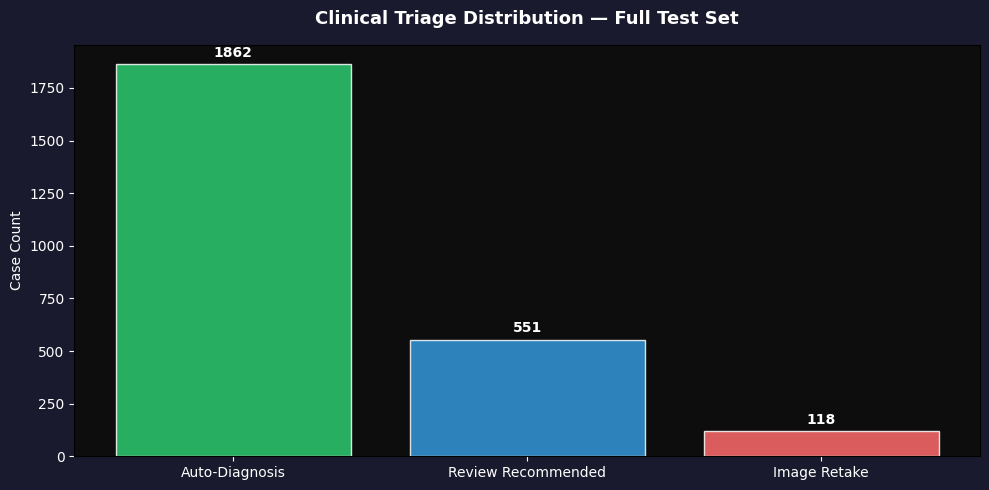


✅ Pipeline Complete. Triage chart saved to /kaggle/working/clinical_reports


In [13]:
# ── CELL 11 : Summary Triage Bar Chart (REFINED) ───────────────────────────────
if 'verdict_counts' in locals() and not final_df.empty:
    fig, ax = plt.subplots(figsize=(10, 5), facecolor='#1a1a2e')
    ax.set_facecolor('#0d0d0d')
    
    # Standard Clinical Colors
    color_palette = {
        'Auto-Diagnosis': '#2ECC71',      # Green
        'Review Recommended': '#3498DB', # Blue
        'Manual Review': '#FFA500',      # Orange
        'Image Retake': '#FF6B6B'        # Red
    }
    
    current_colors = [color_palette.get(x, '#888888') for x in verdict_counts.index]
    
    bars = ax.bar(verdict_counts.index, verdict_counts.values, 
                  color=current_colors, edgecolor='white', alpha=0.85)
    
    ax.set_title("Clinical Triage Distribution — Full Test Set", 
                 color='white', fontsize=13, fontweight='bold', pad=15)
    ax.set_ylabel("Case Count", color='white')
    ax.tick_params(colors='white', labelsize=10)
    
    # Add count labels on top of bars
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + (max(verdict_counts.values)*0.02),
                str(int(b.get_height())), ha='center', color='white', fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'triage_summary.png'), dpi=150, facecolor='#1a1a2e')
    plt.show()
    print(f"\n✅ Pipeline Complete. Triage chart saved to {OUTPUT_DIR}")

## Failure Case Analysis — Why Does the Model Get It Wrong?

This section uses pre-computed XAI heatmaps to analyse **False Positives** and 
**False Negatives**, revealing systematic model biases:

- **False Positive (FP):** Predicted *Malignant*, actually *Benign* → is the model 
focusing on hair, dark corners, or rulers instead of the lesion?
- **False Negative (FN):** Predicted *Benign*, actually *Malignant* → is the model 
ignoring relevant lesion texture?

We also compute an **Attention Drift Score** — what fraction of the heatmap energy 
falls outside the central 50% of the image (i.e. likely focusing on artifacts).


In [14]:
# ── Failure Case Analysis ──────────────────────────────────────────────────────
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.cm as cm
import cv2
from PIL import Image

# ── Helper: load binary ensemble heatmap (use DenseNet as primary) ─────────────
def load_binary_hmap_for_id(image_id, file_idx=None, display_size=224):
    """Try all 3 binary subdirs; return first found."""
    for subdir in ['heatmaps_densenet', 'heatmaps_efficientnet', 'heatmaps_swin', 'heatmaps_convnext', 'heatmaps_resnet']:
        fpath = os.path.join(BINARY_HEATMAP_DIR, subdir, f'{image_id}.npy')
        if not os.path.exists(fpath) and file_idx is not None:
            fpath = os.path.join(BINARY_HEATMAP_DIR, subdir, f'{file_idx}.npy')
        if os.path.exists(fpath):
            hm = np.load(fpath).astype(np.float32)
            import torch, torch.nn.functional as F
            t = torch.from_numpy(hm).unsqueeze(0).unsqueeze(0)
            t = F.interpolate(t, (display_size, display_size),
                              mode='bilinear', align_corners=False)
            return t.squeeze().numpy()
    return None


def attention_drift_score(hmap, centre_fraction=0.5):
    """Fraction of heatmap energy OUTSIDE the central crop.
    High score (>0.5) means the model is looking at image edges/artifacts.
    """
    if hmap is None:
        return float('nan')
    H, W = hmap.shape
    pad_h = int(H * (1 - centre_fraction) / 2)
    pad_w = int(W * (1 - centre_fraction) / 2)
    total = hmap.sum() + 1e-8
    centre = hmap[pad_h:H-pad_h, pad_w:W-pad_w].sum()
    return float(1.0 - centre / total)


# ── Split final_df into FP / FN ────────────────────────────────────────────────
if 'final_df' not in locals() or final_df.empty:
    print('ERROR: Run Cell 9 (batch inference) first to populate final_df.')
else:
    labeled = final_df[final_df['true_label'].notna() & (final_df['true_label'] != -1)].copy()
    labeled['pred_label'] = (labeled['ensemble_prob'] >= CONFIDENCE_THRESHOLD).astype(int)

    fp_df = labeled[(labeled['pred_label'] == 1) & (labeled['true_label'] == 0)]  # said Malignant, was Benign
    fn_df = labeled[(labeled['pred_label'] == 0) & (labeled['true_label'] == 1)]  # said Benign, was Malignant

    print(f'Total labeled cases : {len(labeled)}')
    print(f'False Positives (FP): {len(fp_df)}  (said Malignant, was Benign)')
    print(f'False Negatives (FN): {len(fn_df)}  (said Benign, was Malignant)')

    # Compute attention drift score for all labeled cases
    # --- Monitoring Check to Prevent NaN ---
    if len(labeled) > 0:
        sample_img_id = labeled.iloc[0]['image_id']
        sample_file_idx = labeled.iloc[0].name
        sample_hmap = load_binary_hmap_for_id(sample_img_id, sample_file_idx)
        if sample_hmap is None:
            print(f"⚠️ MONITORING ALERT: Could not load heatmap for image {sample_img_id} (index {sample_file_idx}).")
            print("Drift scores will result in NaN. Halting execution to prevent silent failure.")
            raise FileNotFoundError("Heatmap files are missing or path is incorrect!")
        else:
            print(f"✅ MONITORING SUCCESS: Successfully verified heatmap loading (Matrix shape: {sample_hmap.shape}).")
            print("Drift score computation proceeding safely...")
    labeled['drift_score'] = labeled.apply(
        lambda row: attention_drift_score(load_binary_hmap_for_id(row['image_id'], row.name)), axis=1
    )
    fp_df = labeled[(labeled['pred_label'] == 1) & (labeled['true_label'] == 0)]
    fn_df = labeled[(labeled['pred_label'] == 0) & (labeled['true_label'] == 1)]

    print(f'\nAverage Attention Drift Score:')
    print(f'  All cases  : {labeled["drift_score"].mean():.3f}')
    if len(fp_df) > 0:
        print(f'  FP cases   : {fp_df["drift_score"].mean():.3f}  (higher = more artifact focus)')
    if len(fn_df) > 0:
        print(f'  FN cases   : {fn_df["drift_score"].mean():.3f}')


Total labeled cases : 2531
False Positives (FP): 97  (said Malignant, was Benign)
False Negatives (FN): 123  (said Benign, was Malignant)
✅ MONITORING SUCCESS: Successfully verified heatmap loading (Matrix shape: (224, 224)).
Drift score computation proceeding safely...

Average Attention Drift Score:
  All cases  : 0.449
  FP cases   : 0.456  (higher = more artifact focus)
  FN cases   : 0.431


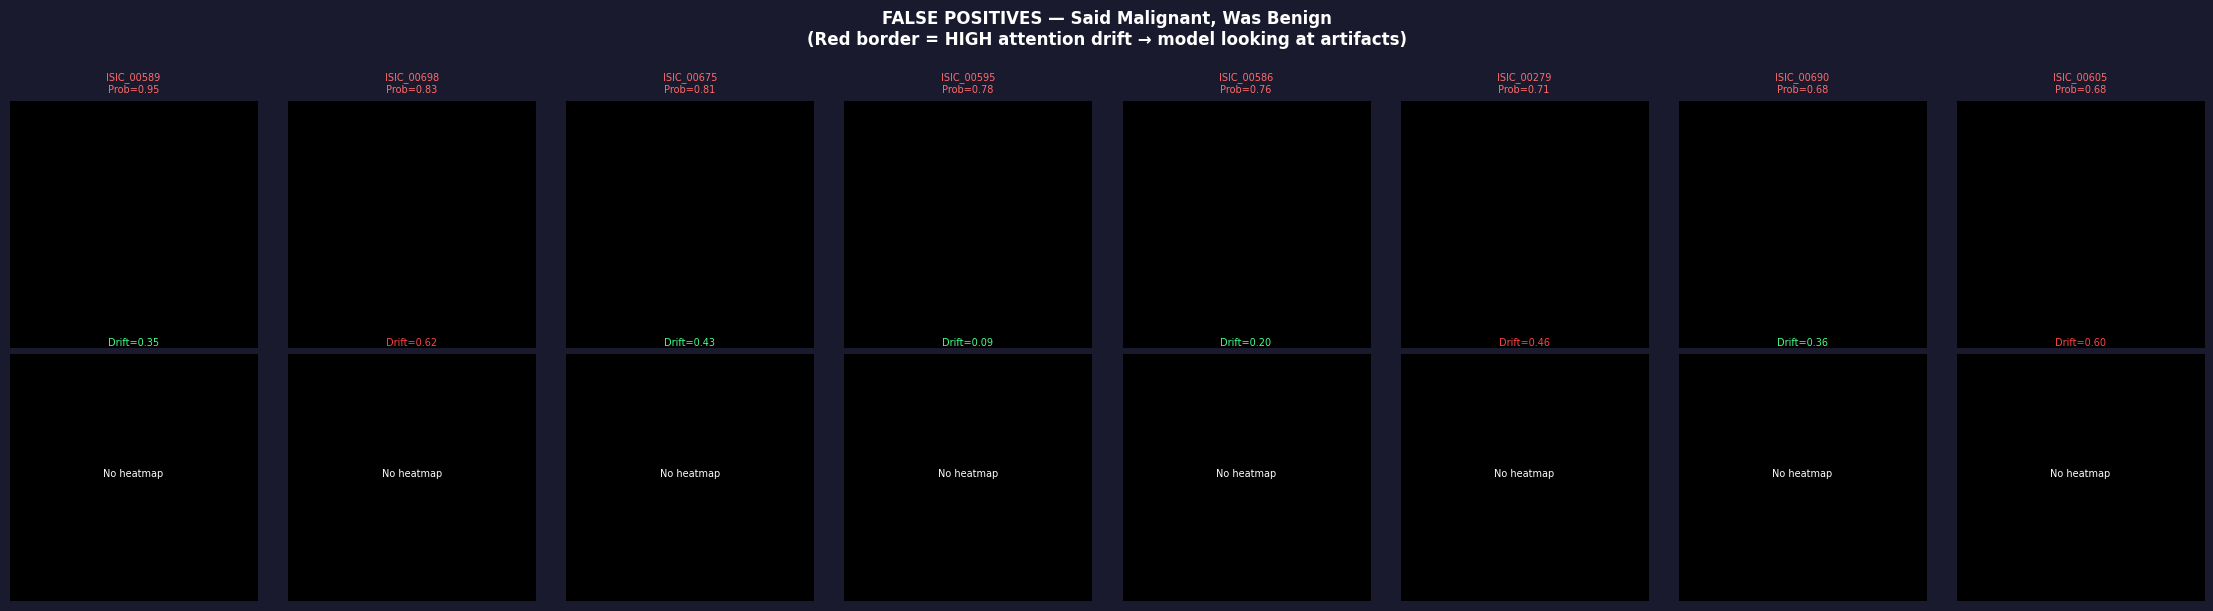

FP panel saved -> failure_false_positives.png


In [15]:
# ── Visual Panel: False Positives ─────────────────────────────────────────────
# Shows top-N FP cases sorted by highest ensemble probability (most confidently wrong)
MAX_SHOW = 8
fp_top = fp_df.nlargest(MAX_SHOW, 'ensemble_prob') if len(fp_df) > 0 else fp_df

if len(fp_top) == 0:
    print('No False Positives found — model has perfect specificity on this set.')
else:
    n = len(fp_top)
    fig, axes = plt.subplots(2, n, figsize=(n * 2.8, 6), facecolor='#1a1a2e')
    fig.suptitle('FALSE POSITIVES — Said Malignant, Was Benign\n'
                 '(Red border = HIGH attention drift → model looking at artifacts)',
                 color='white', fontsize=12, fontweight='bold', y=1.01)

    for col, (_, row) in enumerate(fp_top.iterrows()):
        iid   = str(row['image_id'])
        prob  = row['ensemble_prob']
        drift = row['drift_score']

        # Try to load original image
        img_path = None
        for c in ['image_path', 'path']:
            if c in row and pd.notna(row[c]):
                img_path = row[c]; break
        img_disp = np.zeros((224, 224, 3), dtype=np.float32)
        if img_path and os.path.exists(str(img_path)):
            pil = Image.open(img_path).convert('RGB').resize((224, 224))
            img_disp = np.array(pil).astype(np.float32) / 255.

        hmap = load_binary_hmap_for_id(iid)

        # Row 0: original image
        ax0 = axes[0, col] if n > 1 else axes[0]
        ax0.imshow(img_disp)
        ax0.set_title(f'{iid[:10]}\nProb={prob:.2f}', color='#ff6b6b', fontsize=7)
        ax0.axis('off')

        # Row 1: heatmap overlay — red border if drift > 0.45
        ax1 = axes[1, col] if n > 1 else axes[1]
        if hmap is not None:
            overlay = np.clip(0.55 * img_disp + 0.45 * cm.jet(hmap)[..., :3], 0, 1)
            ax1.imshow(overlay)
        else:
            ax1.imshow(img_disp)
            ax1.text(0.5, 0.5, 'No heatmap', transform=ax1.transAxes,
                     ha='center', color='white', fontsize=7)
        border_col = '#ff4444' if (not np.isnan(drift) and drift > 0.45) else '#44ff88'
        for spine in ax1.spines.values():
            spine.set_edgecolor(border_col); spine.set_linewidth(2)
        ax1.set_title(f'Drift={drift:.2f}', color=border_col, fontsize=7)
        ax1.axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'failure_false_positives.png'),
                dpi=150, bbox_inches='tight', facecolor='#1a1a2e')
    plt.show(); plt.close()
    print(f'FP panel saved -> failure_false_positives.png')


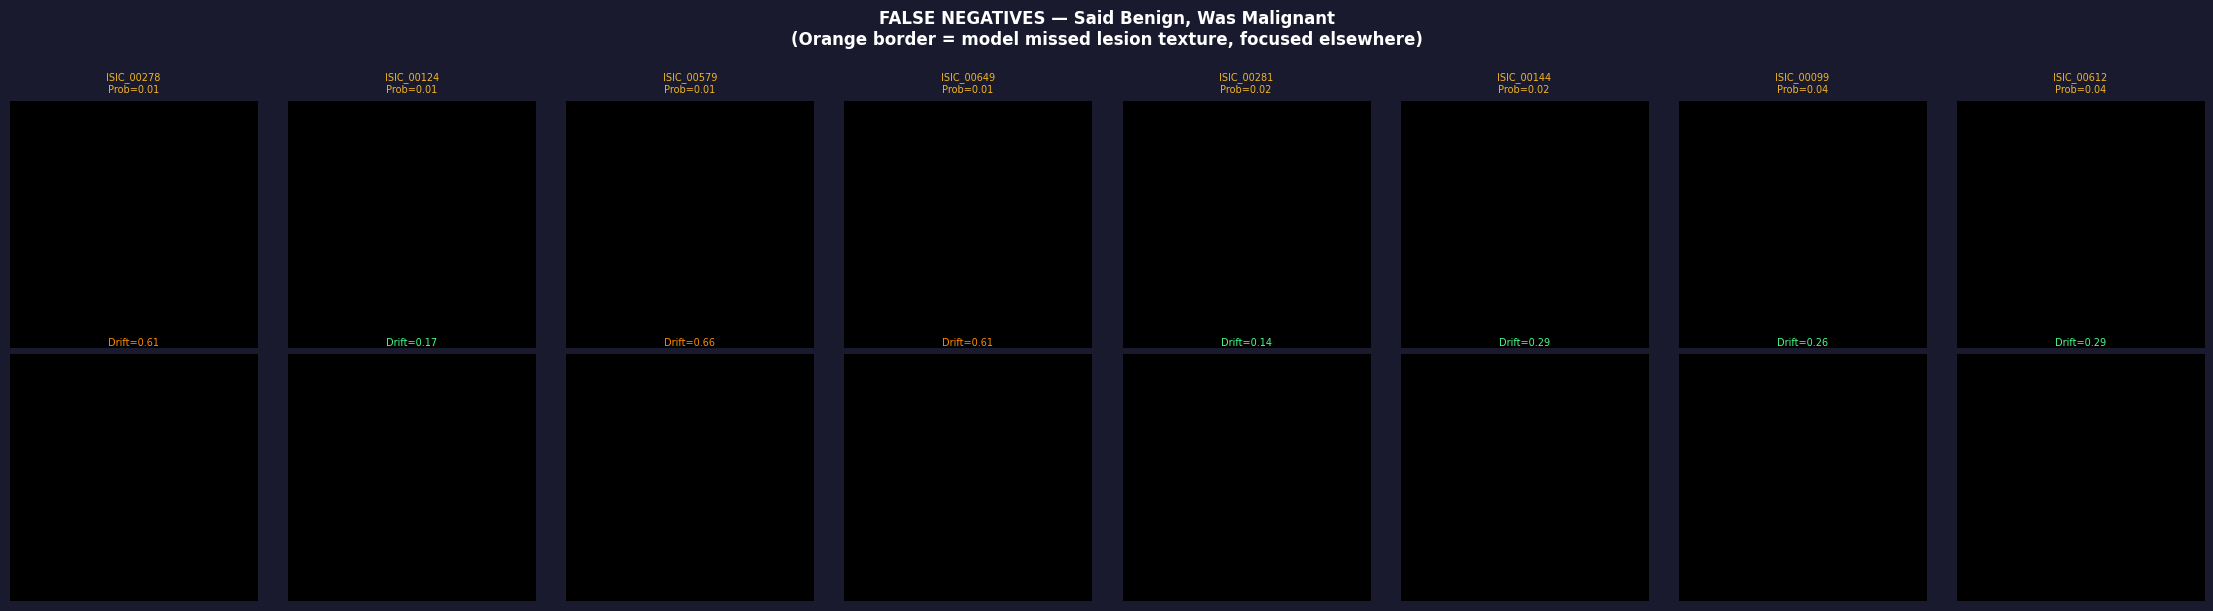

FN panel saved -> failure_false_negatives.png


In [16]:
# ── Visual Panel: False Negatives ─────────────────────────────────────────────
# Shows top-N FN cases sorted by LOWEST ensemble probability (most confidently wrong)
MAX_SHOW = 8
fn_top = fn_df.nsmallest(MAX_SHOW, 'ensemble_prob') if len(fn_df) > 0 else fn_df

if len(fn_top) == 0:
    print('No False Negatives found — model has perfect sensitivity on this set.')
else:
    n = len(fn_top)
    fig, axes = plt.subplots(2, n, figsize=(n * 2.8, 6), facecolor='#1a1a2e')
    fig.suptitle('FALSE NEGATIVES — Said Benign, Was Malignant\n'
                 '(Orange border = model missed lesion texture, focused elsewhere)',
                 color='white', fontsize=12, fontweight='bold', y=1.01)

    for col, (_, row) in enumerate(fn_top.iterrows()):
        iid   = str(row['image_id'])
        prob  = row['ensemble_prob']
        drift = row['drift_score']

        img_path = None
        for c in ['image_path', 'path']:
            if c in row and pd.notna(row[c]):
                img_path = row[c]; break
        img_disp = np.zeros((224, 224, 3), dtype=np.float32)
        if img_path and os.path.exists(str(img_path)):
            pil = Image.open(img_path).convert('RGB').resize((224, 224))
            img_disp = np.array(pil).astype(np.float32) / 255.

        hmap = load_binary_hmap_for_id(iid)

        ax0 = axes[0, col] if n > 1 else axes[0]
        ax0.imshow(img_disp)
        ax0.set_title(f'{iid[:10]}\nProb={prob:.2f}', color='#f0b429', fontsize=7)
        ax0.axis('off')

        ax1 = axes[1, col] if n > 1 else axes[1]
        if hmap is not None:
            overlay = np.clip(0.55 * img_disp + 0.45 * cm.jet(hmap)[..., :3], 0, 1)
            ax1.imshow(overlay)
        else:
            ax1.imshow(img_disp)
        border_col = '#ff8c00' if (not np.isnan(drift) and drift > 0.45) else '#44ff88'
        for spine in ax1.spines.values():
            spine.set_edgecolor(border_col); spine.set_linewidth(2)
        ax1.set_title(f'Drift={drift:.2f}', color=border_col, fontsize=7)
        ax1.axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'failure_false_negatives.png'),
                dpi=150, bbox_inches='tight', facecolor='#1a1a2e')
    plt.show(); plt.close()
    gc.collect() # Force memory release
    print(f'FN panel saved -> failure_false_negatives.png')


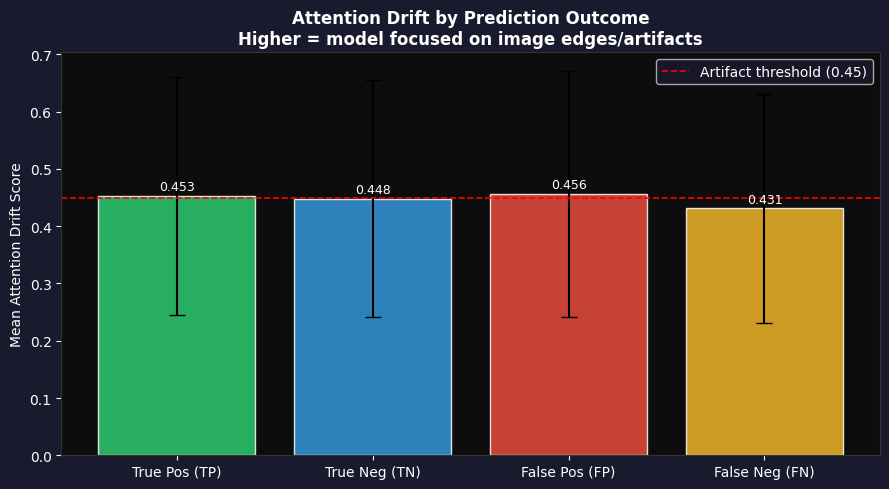


=== Failure Analysis Summary ===
  True Pos (TP)       : n= 809  drift_mean=0.453  drift_std=0.207
  True Neg (TN)       : n=1502  drift_mean=0.448  drift_std=0.207
  False Pos (FP)      : n=  97  drift_mean=0.456  drift_std=0.214
  False Neg (FN)      : n= 123  drift_mean=0.431  drift_std=0.199

  FP drift vs TP drift: 0.456 vs 0.453
  -> FP and TP cases show similar drift. Error likely due to
     genuine lesion ambiguity, not artifact bias.


In [17]:
# ── Attention Drift Summary ────────────────────────────────────────────────────
import pandas as pd

if 'labeled' in locals() and not labeled.empty:
    groups = {
        'True Pos (TP)' : labeled[(labeled['pred_label']==1)&(labeled['true_label']==1)]['drift_score'],
        'True Neg (TN)' : labeled[(labeled['pred_label']==0)&(labeled['true_label']==0)]['drift_score'],
        'False Pos (FP)': fp_df['drift_score'],
        'False Neg (FN)': fn_df['drift_score'],
    }
    labels_g  = [k for k, v in groups.items() if len(v) > 0]
    means_g   = [groups[k].mean()  for k in labels_g]
    stds_g    = [groups[k].std()   for k in labels_g]
    colors_g  = ['#2ecc71', '#3498db', '#e74c3c', '#f0b429'][:len(labels_g)]

    fig, ax = plt.subplots(figsize=(9, 5), facecolor='#1a1a2e')
    ax.set_facecolor('#0d0d0d')
    bars = ax.bar(labels_g, means_g, yerr=stds_g, color=colors_g,
                  capsize=6, alpha=0.85, edgecolor='white')
    ax.axhline(0.45, color='red', ls='--', lw=1.2, label='Artifact threshold (0.45)')
    ax.set_ylabel('Mean Attention Drift Score', color='white')
    ax.set_title('Attention Drift by Prediction Outcome\n'
                 'Higher = model focused on image edges/artifacts',
                 color='white', fontweight='bold')
    ax.tick_params(colors='white')
    ax.legend(facecolor='#1a1a2e', labelcolor='white')
    for spine in ax.spines.values(): spine.set_edgecolor('#333')
    for bar, m in zip(bars, means_g):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                f'{m:.3f}', ha='center', color='white', fontsize=9)

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'attention_drift_by_outcome.png'),
                dpi=150, bbox_inches='tight', facecolor='#1a1a2e')
    plt.show(); plt.close()

    print('\n=== Failure Analysis Summary ===')
    for k in labels_g:
        v = groups[k]
        print(f'  {k:20s}: n={len(v):4d}  drift_mean={v.mean():.3f}  drift_std={v.std():.3f}')
    if len(fp_df) > 0 and len(labeled[(labeled["pred_label"]==1)&(labeled["true_label"]==1)]) > 0:
        fp_drift = fp_df["drift_score"].mean()
        tp_drift = labeled[(labeled["pred_label"]==1)&(labeled["true_label"]==1)]["drift_score"].mean()
        print(f'\n  FP drift vs TP drift: {fp_drift:.3f} vs {tp_drift:.3f}')
        if fp_drift > tp_drift + 0.05:
            print('  -> FP cases show higher artifact focus than TP. Model is likely')
            print('     being fooled by non-lesion features (hair, rulers, skin markings).')
        else:
            print('  -> FP and TP cases show similar drift. Error likely due to')
            print('     genuine lesion ambiguity, not artifact bias.')
